In [1]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns
import matplotlib

from cycler import cycler

color=['0.0', '0.4', '0.8']
default_cycler = (cycler(color=color))
linestyle=['-', '--', ':', '-.']
marker=['o', 'v', 'd', 'p']

plt.rc('axes', prop_cycle=default_cycler)

In [2]:
# =============================================================================
#  APPLY THEME  --  Beamer "Madrid" look. Re-run any time to refresh styling.
# =============================================================================
from pywrangling.jupyter_slides_functions import apply_beamer_theme
from pywrangling.graphing_functions import use_plotplainblind, set_top_ylabel
import course_helpers as chh
from fklearn.causal.validation.curves import relative_cumulative_gain_curve
from fklearn.causal.validation.auc import area_under_the_relative_cumulative_gain_curve
apply_beamer_theme(
    "madrid",
    skip_font_download=True,
    author="Robert Pettis",
    date="Fall 2026",
    show_slide_number=True,
    cell_tags=True,
    notebook_path="17-Meta-Learners.ipynb",
)

<IPython.core.display.Javascript object>


✓ Cell tag CSS applied for 32 cell(s):
 cell_index   slide_id                                  tags
         10            slide_hide_prompt, slide_remove_input
         11            slide_hide_prompt, slide_remove_input
         15  slide-2-3 slide_hide_prompt, slide_remove_input
         16            slide_hide_prompt, slide_remove_input
         17            slide_hide_prompt, slide_remove_input
         18            slide_hide_prompt, slide_remove_input
         20  slide-2-4 slide_hide_prompt, slide_remove_input
         22  slide-2-5 slide_hide_prompt, slide_remove_input
         26  slide-2-8 slide_hide_prompt, slide_remove_input
         29 slide-2-10 slide_hide_prompt, slide_remove_input
         30 slide-2-10 slide_hide_prompt, slide_remove_input
         31 slide-2-10 slide_hide_prompt, slide_remove_input
         32 slide-2-10 slide_hide_prompt, slide_remove_input
         35            slide_hide_prompt, slide_remove_input
         36            slide_hide_prompt, sli

In [3]:
# Presenter clicker remap. Guarded so a student's Restart & Run All
# never breaks on it if pywrangling is missing.
try:
    from pywrangling.jupyter_slides_functions import enable_reveal_key_remap
    enable_reveal_key_remap({
        38: "left",         # Up arrow   -> previous  (clicker left button)
        40: "right",        # Down arrow -> next      (clicker right button)
        27: "up",           # Escape     -> up        (clicker play button)
        66: "down",         # B          -> down      (clicker stop button)
        116: None,          # F5         -> block refresh
        9:  "togglePause",  # Tab        -> black screen
    })
except Exception:
    pass  # not presenting, or pywrangling not installed

<div class="beamer-meta" data-author="Robert Pettis" data-date="Fall 2026"></div>

# Metalearners

### Causal Machine Learning

<br>

<b style="color:#73000A;">Robert Pettis</b>
Fall 2026

## Before We Start: Updating Your Repo

<span style="display:inline-block; background:#73000A; color:#fff; padding:2px 12px; border-radius:8px; font-weight:700; font-size:.9em;">Reminder</span> &nbsp;same git rhythm as the setup lecture.

| command | what it does |
|---|---|
| `git pull upstream main` | grab today's lecture before class |
| `git checkout -b ps1` | a branch for your own work |
| `git add .` then `git commit -m "..."` | snapshot your changes |
| `git push origin ps1` | send it to your fork, then open a pull request |
| `git status` | what changed, any time |

### Last Time: Effect Heterogeneity

- Treatment effects <b style="color:#73000A;">differ across people</b>, and the average can hide that
- $\tau(x)$ is the effect for someone with characteristics $x$
- An interaction gets you a <b style="color:#73000A;">straight line</b> version of it
- Judge it by <b style="color:#73000A;">how well it ranks people</b>, not by fit


### Where We Are Going

- Chapter 6 asked for the CATE. Today we build estimators for it
- <b style="color:#73000A;">Metalearners:</b> recipes that wrap ANY machine learning model
- Discrete treatment first (T, X), then continuous (S)
- Finish with <b style="color:#73000A;">double ML</b>, which is FWL from chapter 4 with ML inside
- Each learner is defined by the mistake the previous one makes

## The Setup: Recycle Prediction Models for Causal Inference

- Heterogeneous treatment effects: units respond differently to treatment
- CATE = $E[Y_1 - Y_0 | X = x]$, the conditional effect
- Metalearners: flexible ML algorithms to estimate CATE
- Bonus: repurpose any predictive model for causal inference
- A metalearner is <b style="color:#73000A;">only as good as the model inside it</b>: try several and compare

### Four Learners, One Goal

All four estimate $\tau(x)$ by recombining <b style="color:#73000A;">prediction models you already know how to fit</b>:

| Learner | Models fit | The move |
|---|---|---|
| T | $\hat{\mu}_0(x),\ \hat{\mu}_1(x)$ | one outcome model per arm, subtract |
| S | $\hat{\mu}(x, t)$ | one model, treatment as a feature |
| X | $\hat{\mu}_t$, then $\hat{\tau}_t$, and $\hat{e}(x)$ | impute effects across arms, blend |
| R / Double-ML | $\hat{m}(x),\ \hat{e}(x)$, then $\hat{\tau}(x)$ | residualize both, regress residuals |

- "Meta" because each is a <b style="color:#73000A;">recipe over learners</b>, not a new estimator: any regression method can sit in each slot

## Metalearners for Discrete Treatments

Setup: marketing email to customers. Treatment: email yes/no. Outcome: purchase volume next month.
Data: observational (biased) and randomized (unbiased).

- Treatment $T$ and outcome $Y$ are observed for each customer
- Covariates $X$ affect both $T$ and $Y$ (confounding)
- Goal: estimate CATE, the effect for each customer

In [4]:
pd.set_option('display.max_columns', 8)

In [5]:
import pandas as pd
import numpy as np

data_biased = pd.read_csv("./data/email_obs_data.csv")
data_rnd = pd.read_csv("./data/email_rnd_data.csv")

print(len(data_biased), len(data_rnd))
data_rnd.head()

300000 10000


,mkt_email,next_mnth_pv,age,tenure,...,jewel,books,music_books_movies,health
0,0,244.26,61.0,1.0,...,1,0,0,2
1,0,29.67,36.0,1.0,...,1,0,2,2
2,0,11.73,64.0,0.0,...,0,1,0,1
3,0,41.41,74.0,0.0,...,0,4,1,0
4,0,447.89,59.0,0.0,...,1,1,2,1


### Fit on Biased Data, Grade on Random Data

- <b style="color:#73000A;">300,000</b> customers from past campaigns: plenty of data, but marketing chose who got the email
- <b style="color:#73000A;">10,000</b> customers from an experiment where the email was randomized
- <b style="color:#73000A;">Train</b> every learner on the big observational set
- <b style="color:#73000A;">Evaluate</b> on the small random set, where the gain curve can be trusted
- Covariates: age, tenure, and purchases by category. They drive who got the email and how much it helps

### Causal Inference Libraries

Most metalearners are implemented in:
- <b style="color:#73000A;">econml</b> (Microsoft): S/T/X/DR learners, DML, very mature
- <b style="color:#73000A;">causalml</b> (Uber): similar coverage, simpler API
- Facure fits LightGBM. We use scikit-learn's `HistGradientBoostingRegressor`, the same kind of boosted trees

In practice, you would use one of these. Here we build from scratch to see the mechanics.

### T-Learner

Simplest: fit one outcome model per treatment arm.

- $\hat{\mu}_0(X) = E[Y | T=0, X]$ (model on control units)
- $\hat{\mu}_1(X) = E[Y | T=1, X]$ (model on treated units)
- Then: $\hat{\tau}(X) = \hat{\mu}_1(X) - \hat{\mu}_0(X)$

### T-Learner: One Model per Arm, Then Subtract

1. Split the sample by arm: $\{i : T_i = 1\}$ and $\{i : T_i = 0\}$
2. Fit $\hat{\mu}_1(x)$ on the treated, $\hat{\mu}_0(x)$ on the controls, any learner you like
3. Predict <b style="color:#73000A;">both</b> for every unit and subtract:
$$\widehat{\tau}(x) = \hat{\mu}_1(x) - \hat{\mu}_0(x)$$

- Once treatment is unconfounded given $x$, each $\hat{\mu}_t$ estimates a real conditional mean, and the difference estimates the CATE
- The quiet cost: each model sees <b style="color:#73000A;">only its own arm's data</b>

### The T-Learner Architecture

- <b style="color:#73000A;">Training:</b> one model $M_0(X)$ on $T=0$ units; another $M_1(X)$ on $T=1$ units
- <b style="color:#73000A;">Prediction:</b> evaluate both on new $X$; CATE is the difference

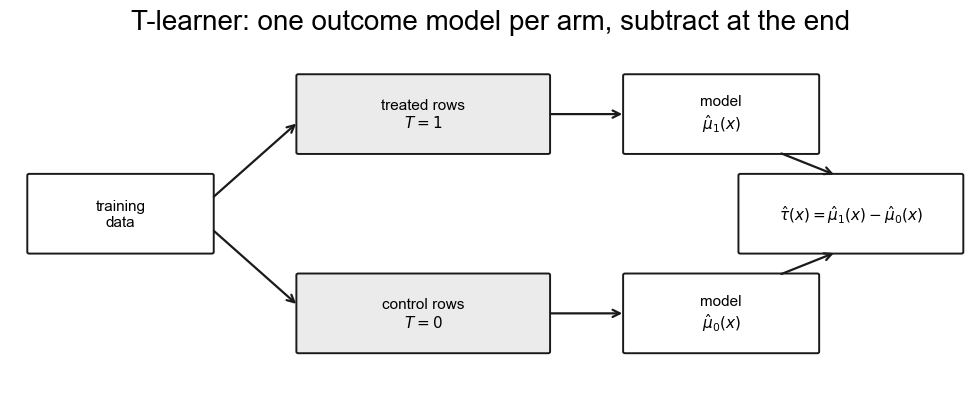

In [6]:
# T-learner architecture
use_plotplainblind("mono")
def _arch_box(ax, x, y, w, h, text, shade="1.0"):
    from matplotlib.patches import FancyBboxPatch
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02",
                                facecolor=shade, edgecolor="0.1", lw=1.4))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=11)


def _arch_arrow(ax, x0, y0, x1, y1):
    ax.annotate("", xy=(x1, y1), xytext=(x0, y0),
                arrowprops=dict(arrowstyle="->", lw=1.6, color="0.1"))

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.set_xlim(0, 10); ax.set_ylim(0, 4.6); ax.axis("off")
_arch_box(ax, 0.2, 1.8, 1.9, 1.0, "training\ndata")
_arch_box(ax, 3.0, 3.1, 2.6, 1.0, "treated rows\n$T=1$", "0.92")
_arch_box(ax, 3.0, 0.5, 2.6, 1.0, "control rows\n$T=0$", "0.92")
_arch_box(ax, 6.4, 3.1, 2.0, 1.0, "model\n$\\hat{\\mu}_1(x)$")
_arch_box(ax, 6.4, 0.5, 2.0, 1.0, "model\n$\\hat{\\mu}_0(x)$")
_arch_box(ax, 7.6, 1.8, 2.3, 1.0,
          "$\\hat{\\tau}(x) = \\hat{\\mu}_1(x) - \\hat{\\mu}_0(x)$")
_arch_arrow(ax, 2.1, 2.5, 3.0, 3.5)
_arch_arrow(ax, 2.1, 2.1, 3.0, 1.1)
_arch_arrow(ax, 5.6, 3.6, 6.4, 3.6)
_arch_arrow(ax, 5.6, 1.0, 6.4, 1.0)
_arch_arrow(ax, 8.0, 3.1, 8.6, 2.8)
_arch_arrow(ax, 8.0, 1.5, 8.6, 1.8)
ax.set_title("T-learner: one outcome model per arm, subtract at the end")
plt.tight_layout()
plt.show()

In [7]:
y = "next_mnth_pv"
T = "mkt_email"
X = list(data_rnd.drop(columns=[y, T]).columns)

train, test = data_biased, data_rnd

In [8]:
from sklearn.ensemble import HistGradientBoostingRegressor

np.random.seed(123)

m0 = HistGradientBoostingRegressor()
m1 = HistGradientBoostingRegressor()

m0.fit(train.query(f"{T}==0")[X], train.query(f"{T}==0")[y])
m1.fit(train.query(f"{T}==1")[X], train.query(f"{T}==1")[y]);

In [9]:
t_learner_cate_test = test.assign(
    cate=m1.predict(test[X]) - m0.predict(test[X])
)

### The T-Learner Orders Customers Well Here

- Sorted by $\hat{\tau}(x)$, the randomized customers at the top of the list really do respond more
- The curve bows well above the baseline. A reasonable first choice for a discrete treatment, mostly because it is simple

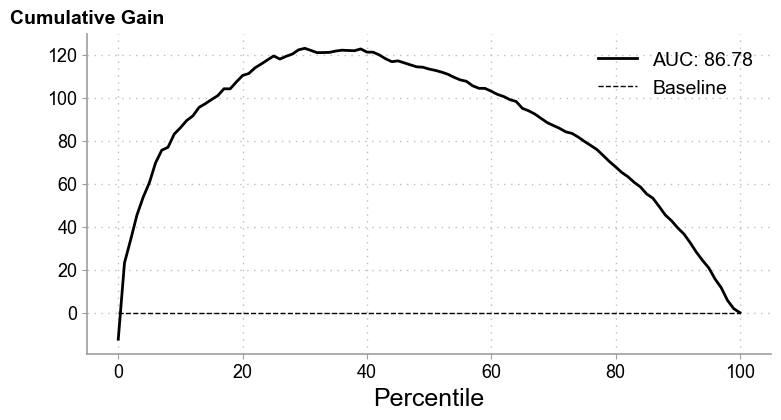

In [10]:
gain_curve_test = relative_cumulative_gain_curve(t_learner_cate_test, "mkt_email", "next_mnth_pv", prediction="cate")
auc = area_under_the_relative_cumulative_gain_curve(t_learner_cate_test, "mkt_email", "next_mnth_pv", prediction="cate")

use_plotplainblind("mono")
fig, ax = plt.subplots(figsize=(8, 4.4))
ax.plot(gain_curve_test, color="black", linewidth=2, label=f"AUC: {auc:.2f}")
ax.hlines(0, 0, 100, linestyle="--", color="black", linewidth=1, label="Baseline")
ax.set_xlabel("Percentile")
set_top_ylabel(ax, "Cumulative Gain", fontsize=14, fontweight="bold")
ax.legend(loc="upper right")
plt.tight_layout()

### A Thin Arm Gets a Simpler Model, and the CATE Inherits the Gap

- Common setup: treatment is expensive, so <b style="color:#73000A;">few treated</b> (50) and <b style="color:#73000A;">many controls</b> (500)
- The outcome has a bump in $x$, but the true effect is a constant $1$
- $\hat{\mu}_0$ has enough data to learn the bump. $\hat{\mu}_1$ <b style="color:#73000A;">self-regularizes</b> (at least 25 points per leaf) and stays nearly flat
- Each model predicts well for its own sample size. The trouble is only in the difference
- $\hat{\tau}(x) = \hat{\mu}_1(x) - \hat{\mu}_0(x)$ shows the bump upside down: <b style="color:#73000A;">fake heterogeneity</b>

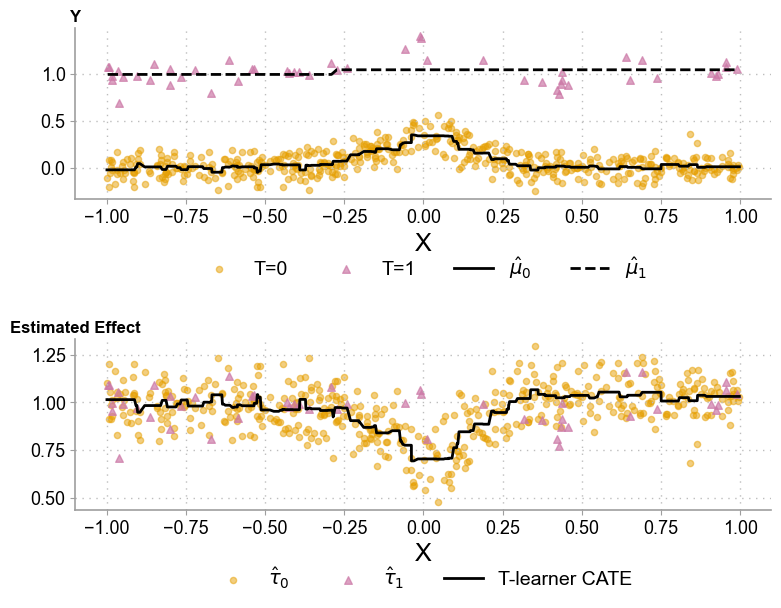

In [11]:
# Illustration: nonlinear outcome, sparse treated data
# Following Facure cell 11
from sklearn.ensemble import HistGradientBoostingRegressor
import warnings
warnings.filterwarnings("ignore", message="X has feature names")
use_plotplainblind("mono")

np.random.seed(123)

def g_kernel(x, c=0, s=0.05):
    return np.exp((-(x-c)**2)/s)

n0 = 500
x0 = np.random.uniform(-1, 1, n0)
y0 = np.random.normal(0.3*g_kernel(x0), 0.1, n0)

n1 = 50
x1 = np.random.uniform(-1, 1, n1)
y1 = np.random.normal(0.3*g_kernel(x1), 0.1, n1) + 1

df = pd.concat([pd.DataFrame(dict(x=x0, y=y0, t=0)),
                 pd.DataFrame(dict(x=x1, y=y1, t=1))]).sort_values(by="x")

m0 = HistGradientBoostingRegressor(max_depth=5, min_samples_leaf=25)
m1 = HistGradientBoostingRegressor(max_depth=5, min_samples_leaf=25)

m0.fit(x0.reshape(-1, 1), y0)
m1.fit(x1.reshape(-1, 1), y1)

m0_hat = m0.predict(df.query("t==0")[["x"]])
m1_hat = m1.predict(df.query("t==1")[["x"]])

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 6.4))

ax1.scatter(x0, y0, alpha=0.5, label="T=0", marker="o", color="#E69F00", s=20)
ax1.scatter(x1, y1, alpha=0.7, label="T=1", marker="^", color="#CC79A7", s=30)
ax1.plot(df.query("t==0")[["x"]], m0_hat, color="black", linestyle="-", linewidth=2, marker="", label=r"$\hat{\mu}_0$")
ax1.plot(df.query("t==1")[["x"]], m1_hat, color="black", linestyle="--", linewidth=2, marker="", label=r"$\hat{\mu}_1$")
set_top_ylabel(ax1, "Y", fontsize=12, fontweight="bold")
ax1.set_xlabel("X")
ax1.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=4, frameon=False)

tau_0 = m1.predict(df.query("t==0")[["x"]]) - df.query("t==0")["y"]
tau_1 = df.query("t==1")["y"] - m0.predict(df.query("t==1")[["x"]])

ax2.scatter(df.query("t==0")[["x"]], tau_0, label=r"$\hat{\tau}_0$", alpha=0.5, marker="o", color="#E69F00", s=20)
ax2.scatter(df.query("t==1")[["x"]], tau_1, label=r"$\hat{\tau}_1$", alpha=0.7, marker="^", color="#CC79A7", s=30)
ax2.plot(df[["x"]], m1.predict(df[["x"]]) - m0.predict(df[["x"]]), label="T-learner CATE", color="black", linewidth=2, marker="")
ax2.set_xlabel("X")
set_top_ylabel(ax2, "Estimated Effect", fontsize=12, fontweight="bold")
ax2.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=4, frameon=False)

plt.tight_layout()

### X-Learner

Two-stage approach to handle imbalanced treatment/control.

<b style="color:#73000A;">Stage 1:</b> Fit $\hat{\mu}_0$ and $\hat{\mu}_1$ (like T-learner)

<b style="color:#73000A;">Stage 2:</b> Construct pseudo-outcomes and fit models to the treatment effect itself:
- For control units: $\tilde{\tau}(X, T=0) = \hat{\mu}_1(X) - Y$
- For treated units: $\tilde{\tau}(X, T=1) = Y - \hat{\mu}_0(X)$
- Fit $\hat{\mu}_{\tau,0}$ and $\hat{\mu}_{\tau,1}$ to these pseudo-effects

### Purplon and Orangor: Two Experts, Two Planets

- <b style="color:#73000A;">Purplon</b> grew up on the purple planet, where every alien is <b style="color:#73000A;">treated</b>. Tell him an alien's size, age, and diet and he knows how a purple alien like that turns out. He has never seen an orange one
- <b style="color:#73000A;">Orangor</b> grew up on the orange planet, where every alien is <b style="color:#73000A;">untreated</b>. Same skill, orange aliens only
- Stage 1 trains them: Purplon is $\hat{\mu}_1(x)$, Orangor is $\hat{\mu}_0(x)$
- The T-learner asks both about the <b style="color:#73000A;">same</b> alien and subtracts: guess minus guess

### Ask the Other Planet's Expert

- An <b style="color:#73000A;">orange</b> alien walks in. We saw how it turned out. Ask Purplon how an alien like this turns out as a purple:
$$\tilde{\tau}_{0i} = \underbrace{\hat{\mu}_1(X_i)}_{\text{Purplon's guess}} - \underbrace{Y_i}_{\text{what we saw}}$$
- A <b style="color:#73000A;">purple</b> alien walks in. Ask Orangor how it would have turned out as an orange:
$$\tilde{\tau}_{1i} = \underbrace{Y_i}_{\text{what we saw}} - \underbrace{\hat{\mu}_0(X_i)}_{\text{Orangor's guess}}$$
- Every alien now has an effect built from <b style="color:#73000A;">one real outcome and one guess</b>
- <b style="color:#73000A;">Purplon guesses for the oranges. Orangor guesses for the purples.</b> That crossing is the X

### One Imputed Set Is Wrong, the Other Is Right

- Back to 500 controls and 50 treated, true effect $1$ everywhere
- $\tilde{\tau}_0$ (orange) used $\hat{\mu}_1$, the flat model fit on 50 points: <b style="color:#73000A;">wrong</b>, it carries the bump
- $\tilde{\tau}_1$ (purple) used $\hat{\mu}_0$, fit on 500 points: <b style="color:#73000A;">right</b>, centered on $1$
- Stage 2 fits $\hat{\tau}_0(x)$ and $\hat{\tau}_1(x)$ to each set. All that control data cannot save $\hat{\tau}_0$: it inherits Purplon's mistake

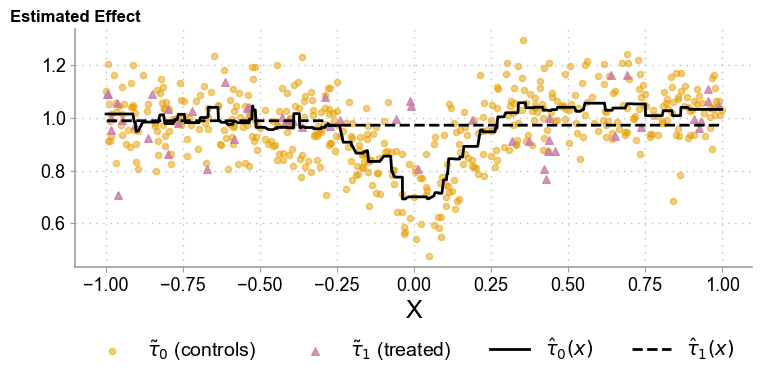

In [12]:
# Facure's second stage on the thin arm example (cell 22 data)
mu_tau0 = HistGradientBoostingRegressor(max_depth=5, min_samples_leaf=25)
mu_tau1 = HistGradientBoostingRegressor(max_depth=5, min_samples_leaf=25)
mu_tau0.fit(df.query("t==0")[["x"]], tau_0)
mu_tau1.fit(df.query("t==1")[["x"]], tau_1)

use_plotplainblind("mono")
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.scatter(df.query("t==0")["x"], tau_0, label=r"$\tilde{\tau}_0$ (controls)", alpha=0.5, marker="o", color="#E69F00", s=20)
ax.scatter(df.query("t==1")["x"], tau_1, label=r"$\tilde{\tau}_1$ (treated)", alpha=0.8, marker="^", color="#CC79A7", s=30)
ax.plot(df.query("t==0")["x"], mu_tau0.predict(df.query("t==0")[["x"]]), color="black", linestyle="-", linewidth=2, marker="", label=r"$\hat{\tau}_0(x)$")
ax.plot(df.query("t==1")["x"], mu_tau1.predict(df.query("t==1")[["x"]]), color="black", linestyle="--", linewidth=2, marker="", label=r"$\hat{\tau}_1(x)$")
ax.set_xlabel("X")
set_top_ylabel(ax, "Estimated Effect", fontsize=12, fontweight="bold")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=4, frameon=False)
plt.tight_layout()

### Blend the Two by the Propensity Score

<b style="color:#73000A;">Prediction:</b> Weight the two Stage 2 models using a propensity score:

$$\hat{\tau}(X) = \hat{e}(X) \cdot \hat{\mu}_{\tau,0}(X) + (1 - \hat{e}(X)) \cdot \hat{\mu}_{\tau,1}(X)$$

where $\hat{e}(X) = P(T=1|X)$ (propensity score).

- Alien version: <b style="color:#73000A;">trust the expert who met more aliens</b>
- Few treated means a small $\hat{e}(x)$, so the weight goes to $\hat{\mu}_{\tau,1}$, built from Orangor's well trained guesses

### The Weights Throw Out the Wrong Imputations

- Point size is the weight each imputed effect gets in the blend
- Orange points get $\hat{e}(x)$, tiny here since only 1 unit in 11 is treated
- Purple points get $1 - \hat{e}(x)$, close to 1
- The X-learner CATE stays near the true effect of $1$, where the T-learner bent with the bump
- In general it helps most when one arm is <b style="color:#73000A;">much larger</b> than the other

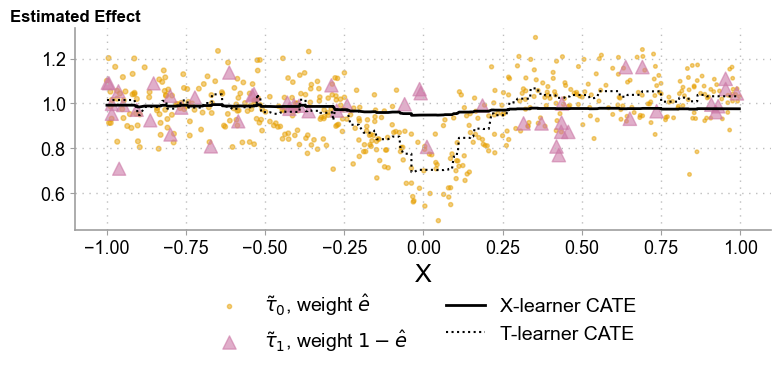

In [13]:
# Facure's propensity blend on the thin arm example
from sklearn.linear_model import LogisticRegression
ps_sim = LogisticRegression(penalty=None).fit(df[["x"]], df["t"]).predict_proba(df[["x"]])[:, 1]
x_cate_sim = (1 - ps_sim)*mu_tau1.predict(df[["x"]]) + ps_sim*mu_tau0.predict(df[["x"]])

use_plotplainblind("mono")
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.scatter(df.query("t==0")["x"], tau_0, label=r"$\tilde{\tau}_0$, weight $\hat{e}$", alpha=0.5, marker="o", color="#E69F00", s=100*ps_sim[df["t"].values == 0])
ax.scatter(df.query("t==1")["x"], tau_1, label=r"$\tilde{\tau}_1$, weight $1-\hat{e}$", alpha=0.6, marker="^", color="#CC79A7", s=100*(1 - ps_sim[df["t"].values == 1]))
ax.plot(df["x"], x_cate_sim, color="black", linewidth=2, marker="", label="X-learner CATE")
ax.plot(df["x"], m1.predict(df[["x"]]) - m0.predict(df[["x"]]), color="black", linestyle=":", linewidth=1.5, marker="", label="T-learner CATE")
ax.set_xlabel("X")
set_top_ylabel(ax, "Estimated Effect", fontsize=12, fontweight="bold")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=2, frameon=False)
plt.tight_layout()

### The X-Learner Architecture

- Kunzel, Sekhon, Bickel, and Yu (2019, *PNAS*) named it: the imputed effects <b style="color:#73000A;">cross</b> arms

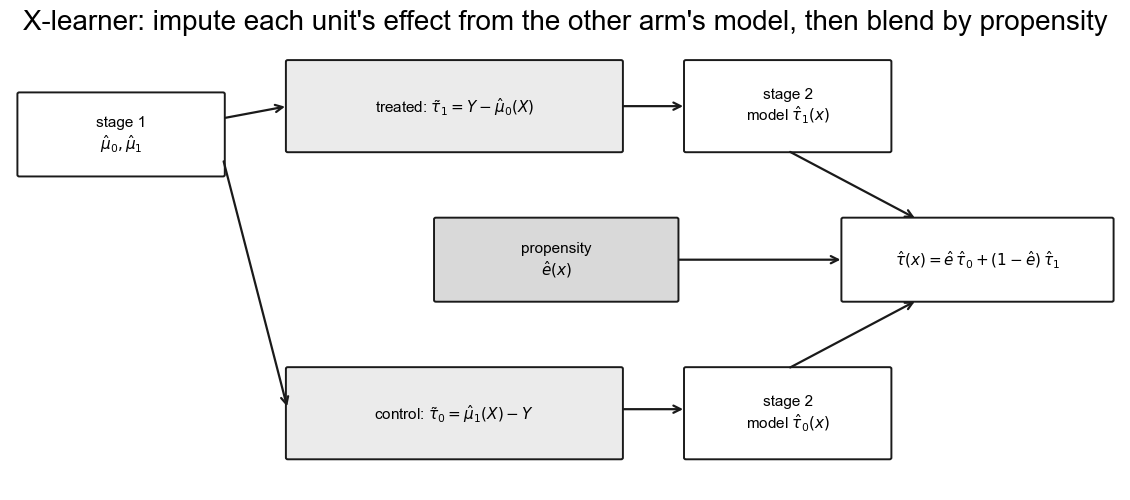

In [12]:
use_plotplainblind("mono")
def _arch_box(ax, x, y, w, h, text, shade="1.0"):
    from matplotlib.patches import FancyBboxPatch
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02",
                                facecolor=shade, edgecolor="0.1", lw=1.4))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=11)


def _arch_arrow(ax, x0, y0, x1, y1):
    ax.annotate("", xy=(x1, y1), xytext=(x0, y0),
                arrowprops=dict(arrowstyle="->", lw=1.6, color="0.1"))

fig, ax = plt.subplots(figsize=(11.5, 5.2))
ax.set_xlim(0, 12); ax.set_ylim(0, 5.6); ax.axis("off")
_arch_box(ax, 0.1, 3.9, 2.2, 1.0, "stage 1\n$\\hat{\\mu}_0, \\hat{\\mu}_1$")
_arch_box(ax, 3.0, 4.2, 3.6, 1.1,
          "treated: $\\tilde{\\tau}_1 = Y - \\hat{\\mu}_0(X)$", "0.92")
_arch_box(ax, 3.0, 0.4, 3.6, 1.1,
          "control: $\\tilde{\\tau}_0 = \\hat{\\mu}_1(X) - Y$", "0.92")
_arch_box(ax, 7.3, 4.2, 2.2, 1.1, "stage 2\nmodel $\\hat{\\tau}_1(x)$")
_arch_box(ax, 7.3, 0.4, 2.2, 1.1, "stage 2\nmodel $\\hat{\\tau}_0(x)$")
_arch_box(ax, 4.6, 2.35, 2.6, 1.0, "propensity\n$\\hat{e}(x)$", "0.85")
_arch_box(ax, 9.0, 2.35, 2.9, 1.0,
          "$\\hat{\\tau}(x) = \\hat{e}\\,\\hat{\\tau}_0 + (1-\\hat{e})\\,\\hat{\\tau}_1$")
_arch_arrow(ax, 2.3, 4.6, 3.0, 4.75)
_arch_arrow(ax, 2.3, 4.1, 3.0, 1.0)
_arch_arrow(ax, 6.6, 4.75, 7.3, 4.75)
_arch_arrow(ax, 6.6, 1.0, 7.3, 1.0)
_arch_arrow(ax, 8.4, 4.2, 9.8, 3.35)
_arch_arrow(ax, 8.4, 1.5, 9.8, 2.35)
_arch_arrow(ax, 7.2, 2.85, 9.0, 2.85)
ax.set_title("X-learner: impute each unit's effect from the other arm's model,"
             " then blend by propensity")
plt.tight_layout()
plt.show()

### X-Learner, as an Algorithm

1. <b style="color:#73000A;">Stage 1</b>: fit $\hat{\mu}_0$ and $\hat{\mu}_1$ per arm, exactly as the T-learner
2. <b style="color:#73000A;">Impute each unit's effect using the other arm's model</b>:
$$\tilde{\tau}_{1i} = Y_i - \hat{\mu}_0(x_i) \quad \text{(treated)}, \qquad \tilde{\tau}_{0i} = \hat{\mu}_1(x_i) - Y_i \quad \text{(controls)}$$
3. <b style="color:#73000A;">Stage 2</b>: regress the imputed effects on $x$, one model per arm: $\hat{\tau}_1(x)$, $\hat{\tau}_0(x)$
4. <b style="color:#73000A;">Blend by propensity</b>:
$$\widehat{\tau}(x) = \hat{e}(x)\,\hat{\tau}_0(x) + \big(1 - \hat{e}(x)\big)\,\hat{\tau}_1(x)$$

### Propensity Score: A Light Aside

- <b style="color:#73000A;">Definition:</b> $e(X) = P(T=1|X)$, the probability a unit gets treated given $X$
- <b style="color:#73000A;">Used in:</b> reweighting (inverse probability weighting), doubly robust methods, domain adaptation
- <b style="color:#73000A;">Back from lecture 15</b>, now as a weight for combining learners
- Model it with logistic regression or any classifier

### Our Code Adds One Twist: Domain Adaptation

- Stage 1 fits each $\hat{\mu}_t$ with weights $1/\hat{P}(T = t \mid X)$
- Each arm's model then learns as if it saw the whole population, not just the customers who landed in that arm
- Facure calls this the <b style="color:#73000A;">domain adaptation learner</b>: the X-learner with a reweighted stage 1
- That is why the propensity model is fit first

In [13]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingRegressor

# propensity score model
ps_model = LogisticRegression(penalty=None)
ps_model.fit(train[X], train[T])

# first stage models (T-learner)
train_t0 = train.query(f"{T}==0")
train_t1 = train.query(f"{T}==1")

m0 = HistGradientBoostingRegressor()
m1 = HistGradientBoostingRegressor()

np.random.seed(123)

m0.fit(train_t0[X], train_t0[y],
       sample_weight=1/ps_model.predict_proba(train_t0[X])[:, 0])

m1.fit(train_t1[X], train_t1[y],
       sample_weight=1/ps_model.predict_proba(train_t1[X])[:, 1]);

In [14]:
# second stage
tau_hat_0 = m1.predict(train_t0[X]) - train_t0[y]
tau_hat_1 = train_t1[y] - m0.predict(train_t1[X])

m_tau_0 = HistGradientBoostingRegressor()
m_tau_1 = HistGradientBoostingRegressor()

np.random.seed(123)

m_tau_0.fit(train_t0[X], tau_hat_0)
m_tau_1.fit(train_t1[X], tau_hat_1);

In [15]:
# estimate the CATE
ps_test = ps_model.predict_proba(test[X])[:, 1]

x_cate_test = test.assign(
    cate=(ps_test*m_tau_0.predict(test[X]) +
          (1-ps_test)*m_tau_1.predict(test[X])
         )
)

### The X-Learner Edges Ahead Here, for a Different Reason

- In the email data the arms are balanced (about 51% treated), so the thin arm problem never shows up
- Still, with our boosted trees the X-learner's AUC beats the T-learner's (about 95 vs 87)
- Facure's LightGBM version has it slightly <b style="color:#73000A;">behind</b>. Which learner wins depends on the data <b style="color:#73000A;">and</b> the model inside it

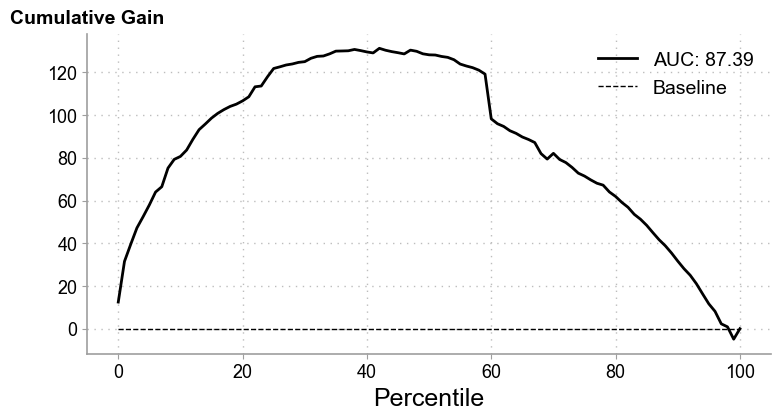

In [16]:
gain_curve_test = relative_cumulative_gain_curve(x_cate_test, "mkt_email", "next_mnth_pv", prediction="cate")
auc = area_under_the_relative_cumulative_gain_curve(x_cate_test, "mkt_email", "next_mnth_pv", prediction="cate")

use_plotplainblind("mono")
fig, ax = plt.subplots(figsize=(8, 4.4))
ax.plot(gain_curve_test, color="black", linewidth=2, label=f"AUC: {auc:.2f}")
ax.hlines(0, 0, 100, linestyle="--", color="black", linewidth=1, label="Baseline")
ax.set_xlabel("Percentile")
set_top_ylabel(ax, "Cumulative Gain", fontsize=14, fontweight="bold")
ax.legend(loc="upper right")
plt.tight_layout()

### Real Minus Guess Beats Guess Minus Guess

When treatment is rare and control abundant:
- T-learner: every effect is <b style="color:#73000A;">guess minus guess</b>, and the thin arm's oversimplified $\hat{\mu}_1$ bends the CATE
- X-learner: every imputed effect is <b style="color:#73000A;">real minus guess</b>, and the weights favor the guesses from the well fed model

In this email dataset, both arms have data, so the advantage is modest.

## Metalearners for Continuous Treatments

Treatment is now a real-valued variable: e.g., discount percent, dose.

- Data: restaurants, discount level, and resulting sales
- Goal: CATE = how much does a 1-unit discount increase sales for each restaurant on each day?
- Use: the higher a day's CATE, the bigger the discount it should get

In [17]:
pd.set_option('display.max_columns', 8)

In [18]:
data_cont = pd.read_csv("./data/discount_data.csv")
data_cont.head()

# Facure's split for the continuous example: train on 2016-2017, test on 2018
train = data_cont.query("day<'2018-01-01'")
test = data_cont.query("day>='2018-01-01'")

### S-Learner

Simplest for continuous treatment: single outcome model with $T$ as a feature.

- Fit $\hat{\mu}(X, T) = E[Y | X, T]$ on all data
- To estimate CATE: construct counterfactual grid
  - For each test unit, replicate across treatment values: $T \in \{0, 10, 20, 30, 40\}$
  - Predict $\hat{Y}$ under each $T$
  - Summarize to a single CATE (e.g., slope via regression)

### S-Learner: The Treatment Is Just Another Feature

1. Fit <b style="color:#73000A;">one</b> model with the treatment as an ordinary feature: $\hat{\mu}(x, t)$
2. Predict every unit twice, treatment switched on and off
3. Subtract:
$$\widehat{\tau}(x) = \hat{\mu}(x, 1) - \hat{\mu}(x, 0) \qquad \text{(discrete)}, \qquad \widehat{\tau}(x) = \frac{\partial \hat{\mu}(x, t)}{\partial t} \quad \text{(continuous)}$$

- One model, all the data, and it extends to continuous treatments for free
- The quiet cost: the learner may decide the treatment is <b style="color:#73000A;">not worth splitting on</b>

### The S-Learner Architecture

- <b style="color:#73000A;">Training:</b> one model on every row, with $T$ as one more column
- <b style="color:#73000A;">Prediction:</b> the same unit at different $T$ values; the CATE is the difference

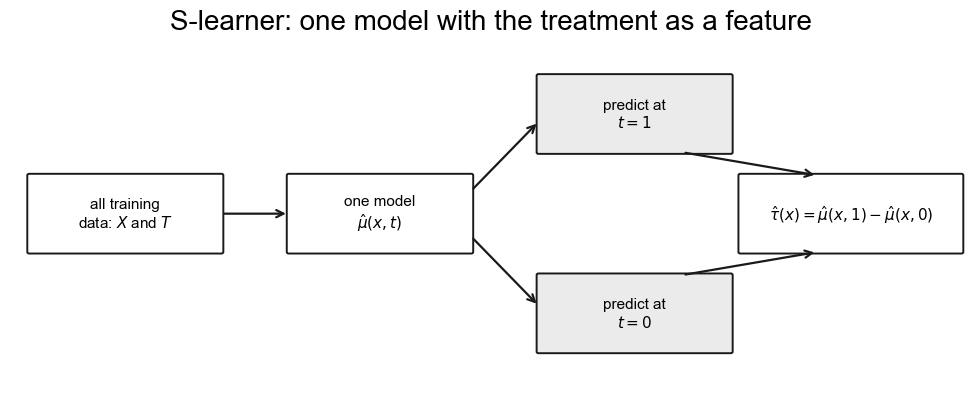

In [21]:
# S-learner architecture
use_plotplainblind("mono")
def _arch_box(ax, x, y, w, h, text, shade="1.0"):
    from matplotlib.patches import FancyBboxPatch
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02",
                                facecolor=shade, edgecolor="0.1", lw=1.4))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=11)


def _arch_arrow(ax, x0, y0, x1, y1):
    ax.annotate("", xy=(x1, y1), xytext=(x0, y0),
                arrowprops=dict(arrowstyle="->", lw=1.6, color="0.1"))

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.set_xlim(0, 10); ax.set_ylim(0, 4.6); ax.axis("off")
_arch_box(ax, 0.2, 1.8, 2.0, 1.0, "all training\ndata: $X$ and $T$")
_arch_box(ax, 2.9, 1.8, 1.9, 1.0, "one model\n$\\hat{\\mu}(x, t)$")
_arch_box(ax, 5.5, 3.1, 2.0, 1.0, "predict at\n$t = 1$", "0.92")
_arch_box(ax, 5.5, 0.5, 2.0, 1.0, "predict at\n$t = 0$", "0.92")
_arch_box(ax, 7.6, 1.8, 2.3, 1.0,
          "$\\hat{\\tau}(x) = \\hat{\\mu}(x,1) - \\hat{\\mu}(x,0)$")
_arch_arrow(ax, 2.2, 2.3, 2.9, 2.3)
_arch_arrow(ax, 4.8, 2.6, 5.5, 3.5)
_arch_arrow(ax, 4.8, 2.0, 5.5, 1.1)
_arch_arrow(ax, 7.0, 3.1, 8.4, 2.8)
_arch_arrow(ax, 7.0, 1.5, 8.4, 1.8)
ax.set_title("S-learner: one model with the treatment as a feature")
plt.tight_layout()
plt.show()

In [19]:
X = ["month", "weekday", "is_holiday", "competitors_price"]
T = "discounts"
y = "sales"

np.random.seed(123)
s_learner = HistGradientBoostingRegressor()
s_learner.fit(train[X+[T]], train[y]);

In [20]:
t_grid = pd.DataFrame(dict(key=1,
                           discounts=np.array([0, 10, 20, 30, 40])))

test_cf = (test
           .drop(columns=["discounts"])
           .assign(key=1)
           .merge(t_grid)
           # make predictions after expansion
           .assign(sales_hat = lambda d: s_learner.predict(d[X+[T]])))

test_cf.head(8)

,rest_id,day,month,weekday,...,sales,key,discounts,sales_hat
0,0,2018-01-01,1,0,...,251.5,1,0,57.890859
1,0,2018-01-01,1,0,...,251.5,1,10,436.603428
2,0,2018-01-01,1,0,...,251.5,1,20,818.600391
3,0,2018-01-01,1,0,...,251.5,1,30,1289.059029
4,0,2018-01-01,1,0,...,251.5,1,40,1514.447226
5,0,2018-01-02,1,1,...,541.0,1,0,70.298692
6,0,2018-01-02,1,1,...,541.0,1,10,513.777707
7,0,2018-01-02,1,1,...,541.0,1,20,1013.522315


### Christmas Responds More to Discounts Than a Day in June

- Each line: one day's predicted sales at discounts of 0, 10, 20, 30, and 40
- A steeper line means customers are more sensitive to discounts that day
- Whether these counterfactual curves are right is a separate question. The gain curve checks the ordering

C:\Users\Owner\AppData\Local\Temp\ipykernel_37860\4047577342.py:8: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.lineplot(data=test_cf.query("day.isin(@days)").query("rest_id==2"),


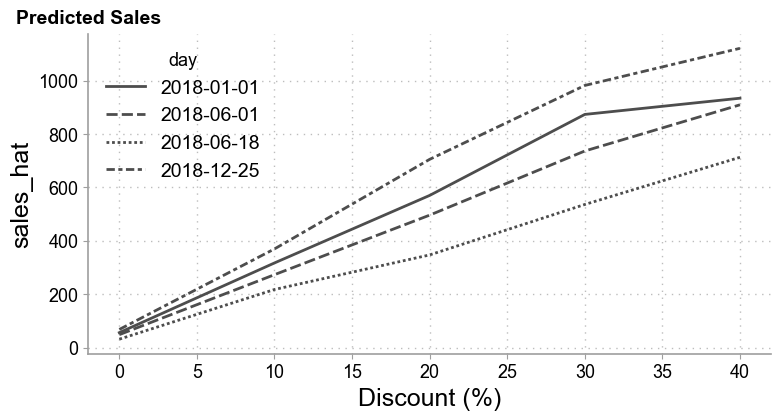

In [21]:
days = ["2018-12-25", "2018-01-01", "2018-06-01", "2018-06-18"]

use_plotplainblind("mono")
fig, ax = plt.subplots(figsize=(8, 4.4))

# Use seaborn lineplot for tidier output
import seaborn as sns
sns.lineplot(data=test_cf.query("day.isin(@days)").query("rest_id==2"),
             y="sales_hat", x="discounts", style="day",
             ax=ax, palette="gray", linewidth=2, marker="")

ax.set_xlabel("Discount (%)")
set_top_ylabel(ax, "Predicted Sales", fontsize=14, fontweight="bold")
plt.tight_layout()

### Summarize Each Day's Curve by Its Slope

- The S-learner gives predictions, not an effect. The gain curve needs one number per day
- Expanded data has one row per (restaurant, day, discount)
- Run regression within each (restaurant, day) group: $Y \sim T$
- Slope = CATE for that unit
- Formula: $\hat{\beta} = \text{Cov}(Y, T) / \text{Var}(T)$

In [22]:
from toolz import curry

@curry
def linear_effect(df, y, t):
    return np.cov(df[y], df[t])[0, 1]/df[t].var()

cate = (test_cf
        .groupby(["rest_id", "day"])
        .apply(linear_effect(t="discounts", y="sales_hat"))
        .rename("cate"))

test_s_learner_pred = test.set_index(["rest_id", "day"]).join(cate)

C:\Users\Owner\AppData\Local\Temp\ipykernel_37860\134438320.py:9: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(linear_effect(t="discounts", y="sales_hat"))


### The S-Learner Is a Good First Bet

- It ranks days well here, though this data is easy: lots of randomized discounts to train on
- One model handles <b style="color:#73000A;">binary and continuous</b> treatments
- Facure's default first try for any causal problem

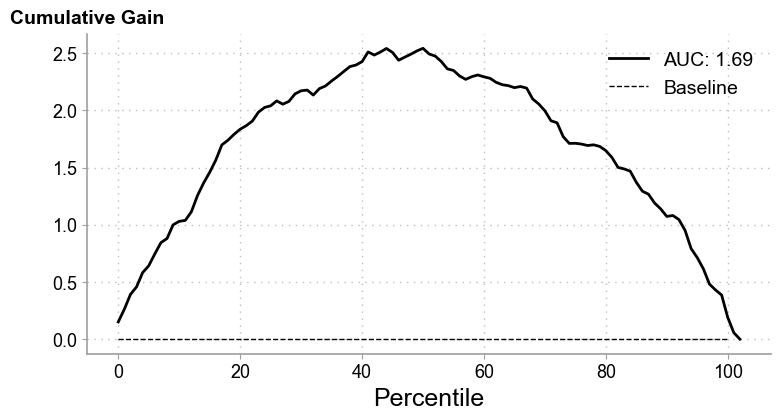

In [23]:
gain_curve_test = relative_cumulative_gain_curve(test_s_learner_pred, "discounts", "sales", prediction="cate")
auc = area_under_the_relative_cumulative_gain_curve(test_s_learner_pred, "discounts", "sales", prediction="cate")

use_plotplainblind("mono")
fig, ax = plt.subplots(figsize=(8, 4.4))
ax.plot(gain_curve_test, color="black", linewidth=2, label=f"AUC: {auc:.2f}")
ax.hlines(0, 0, 100, linestyle="--", color="black", linewidth=1, label="Baseline")
ax.set_xlabel("Percentile")
set_top_ylabel(ax, "Cumulative Gain", fontsize=14, fontweight="bold")
ax.legend(loc="upper right")
plt.tight_layout()

### The S-Learner Shrinks the Effect Toward Zero

S-learner tends to underestimate ATE because:
- Regularization suppresses the treatment coefficient
- If treatment is weak vs. confounders, it gets even lower weight
- 500 simulations with true ATE=1 show distribution left-shifted

In [24]:
np.random.seed(123)

def sim_s_learner_ate():
    n = 10000
    nx = 20

    X = np.random.normal(0, 1, (n, nx))
    coefs_y = np.random.uniform(-1, 1, nx)
    coefs_t = np.random.uniform(-0.5, 0.5, nx)

    ps = 1/(1+np.exp(-(X.dot(coefs_t))))
    t = np.random.binomial(1, ps)
    te = 1

    y = np.random.normal(t*te + X.dot(coefs_y), 1)

    s_learner = HistGradientBoostingRegressor(max_depth=5, verbose=0)
    s_learner.fit(np.concatenate([X, t.reshape(-1, 1)], axis=1), y);

    ate_hat = (s_learner.predict(np.concatenate([X, np.ones((n, 1))], axis=1))
               - s_learner.predict(np.concatenate([X, np.zeros((n, 1))], axis=1))).mean()

    return ate_hat

ates = [sim_s_learner_ate() for _ in range(500)]

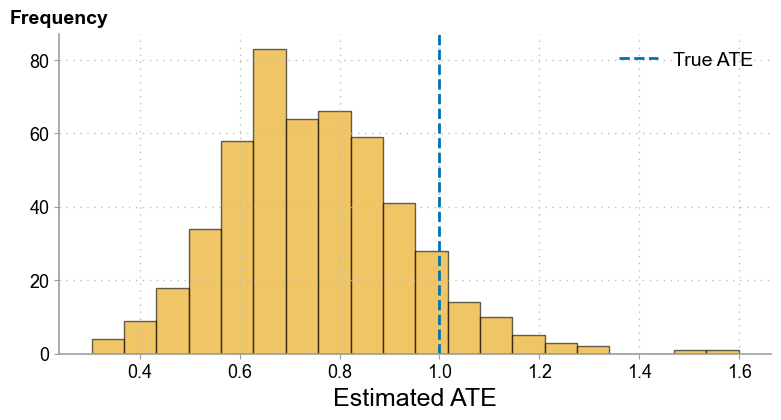

In [25]:
use_plotplainblind("mono")
fig, ax = plt.subplots(figsize=(8, 4.4))
ax.hist(ates, alpha=0.6, bins=20, color="#E69F00", edgecolor="black", linewidth=1)
ax.axvline(1, color="#0072B2", linestyle="--", linewidth=2, label="True ATE")
ax.set_xlabel("Estimated ATE")
set_top_ylabel(ax, "Frequency", fontsize=14, fontweight="bold")
ax.legend()
plt.tight_layout()

## Coming Back to FWL

- Chapter 4: regress $T$ on $X$, regress $Y$ on $X$, relate the residuals
- That was <b style="color:#73000A;">linear</b>. Nothing in the logic required it to be
- Double ML: use any ML model for the two residualizations
- Same two moves you already watched: <b style="color:#73000A;">debias</b>, then <b style="color:#73000A;">denoise</b>
- The payoff: flexible confounding adjustment, still a valid causal estimate

## Double/Debiased Machine Learning (DML)

Core idea: use ML to remove confounding, then regress residuals on residuals.

<b style="color:#73000A;">Step 1:</b> Residualize treatment and outcome
- Cross-validated ML prediction: $\hat{T} = \hat{\mu}_T(X)$, $\hat{Y} = \hat{\mu}_Y(X)$
- Residuals: $\tilde{T} = T - \hat{T}$, $\tilde{Y} = Y - \hat{Y}$

<b style="color:#73000A;">Step 2:</b> Regress residuals
- $\tilde{Y} = \alpha + \tau \tilde{T} + \epsilon$
- Slope $\tau$ is the (debiased) ATE

### Cross-Fitting Keeps Overfitting From Eating the Effect

- Flexible models can overfit, and each kind of overfit does its own damage
- Overfit $\hat{\mu}_Y$: it soaks up part of the $T$ effect, $\tilde{Y}$ shrinks, the slope is <b style="color:#73000A;">biased toward zero</b>
- Overfit $\hat{\mu}_T$: $\tilde{T}$ loses variance, as if everyone got the same treatment, so the slope is <b style="color:#73000A;">noisy</b>
- Fix: <b style="color:#73000A;">out of fold residuals</b>. Fit on $K-1$ folds, predict the held out fold, repeat $K$ times
- In code it is one function: `cross_val_predict`

In [26]:
# ---------------------------------------------------------------------------
# STEP 1: Import the necessary function for cross-validated ML predictions
# ---------------------------------------------------------------------------

from sklearn.model_selection import cross_val_predict

"""
What we're doing:

We are setting up variables for a causal ML workflow:
  - X: covariates / confounders
  - T: treatment variable
  - y: outcome variable

We’ll use ML models to “residualize” (debias and denoise) both T and y,
so that in a later step we can estimate the causal effect of T on y.

This approach is common in:
  - Double Machine Learning (DML)
  - R-learner / partially linear models
  - Debiased ML pipelines

The idea:
  1) Predict T using X (→ expected treatment).
  2) Predict y using X (→ expected outcome if T didn’t exist).
  3) Compute residuals:
      t_res = actual_T   - predicted_T
      y_res = actual_y   - predicted_y
    These residuals are orthogonal to X, which helps remove confounding.
"""


# ---------------------------------------------------------------------------
# STEP 2: Declare variables representing covariates, treatment, and outcome
# ---------------------------------------------------------------------------

X = ["month", "weekday", "is_holiday", "competitors_price"]  # covariates
T = "discounts"                        # treatment
y = "sales"                          # outcome

"""
X are factors that affect both discounts and sales:
  - month, weekday, is_holiday capture seasonality patterns
  - competitors_price captures competitive pressure

We want to estimate the effect of discounts on sales,
AFTER controlling for these confounders.
"""


# ---------------------------------------------------------------------------
# STEP 3: Choose machine learning models for residualization
# ---------------------------------------------------------------------------

debias_m = HistGradientBoostingRegressor(verbose=0)  # Model for predicting T | X (removes confounding)
denoise_m = HistGradientBoostingRegressor(verbose=0)  # Model for predicting y | X (removes noise)

"""
debias_m models discounts given X: T_hat = E[T | X]
denoise_m models sales given X:  y_hat = E[y | X]

We use flexible models (here LightGBM) to capture nonlinearities and interactions.
"""


# ---------------------------------------------------------------------------
# STEP 4: Cross-validated predictions to avoid overfitting
# ---------------------------------------------------------------------------

t_res = train[T] - cross_val_predict(debias_m, train[X], train[T], cv=5)
y_res = train[y] - cross_val_predict(denoise_m, train[X], train[y], cv=5)

"""
We use *cross_val_predict*:
  - Splits data into cv=5 folds.
  - For each fold:
     train on 4 folds, predict on the held-out fold
  - Therefore, each prediction is *out-of-sample*
   → prevents overfitting → crucial for valid residualization

These residuals represent the part of T and y that CANNOT 
be explained by X alone i.e., the variation 'as good as randomized'
with respect to the confounders.
  
t_res = T - E[T | X]  → “unexpected” or “unexplained” part of discounts
y_res = y - E[y | X]  → “unexpected” part of sales after removing calendar/competition effects

Later, you can regress y_res ~ t_res to estimate the causal effect (debiased).
"""

# ---------------------------------------------------------------------------
# NEXT STEP (not included here, but typical)
# ---------------------------------------------------------------------------
# Fit: OLS(y_res ~ t_res) to estimate the treatment effect on sales
# τ̂ = slope of t_res in predicting y_res → causal effect of discounts
# ---------------------------------------------------------------------------


"\nWe use *cross_val_predict*:\n  - Splits data into cv=5 folds.\n  - For each fold:\n     train on 4 folds, predict on the held-out fold\n  - Therefore, each prediction is *out-of-sample*\n   → prevents overfitting → crucial for valid residualization\n\nThese residuals represent the part of T and y that CANNOT \nbe explained by X alone i.e., the variation 'as good as randomized'\nwith respect to the confounders.\n  \nt_res = T - E[T | X]  → “unexpected” or “unexplained” part of discounts\ny_res = y - E[y | X]  → “unexpected” part of sales after removing calendar/competition effects\n\nLater, you can regress y_res ~ t_res to estimate the causal effect (debiased).\n"

In [27]:
from sklearn.model_selection import cross_val_predict

X = ["month", "weekday", "is_holiday", "competitors_price"]
T = "discounts"
y = "sales"

debias_m = HistGradientBoostingRegressor(verbose=0)
denoise_m = HistGradientBoostingRegressor(verbose=0)

t_res = train[T] - cross_val_predict(debias_m, train[X], train[T], cv=5)
y_res = train[y] - cross_val_predict(denoise_m, train[X], train[y], cv=5)

### Residual on Residual Gives the ATE

- Regress $\tilde{Y}$ on $\tilde{T}$: the slope is the average effect of one more point of discount on sales
- Do not trust these standard errors: they ignore that the residuals were estimated

In [28]:
import statsmodels.api as sm

sm.OLS(y_res, t_res).fit().summary().tables[1]

,coef,std err,t,P>|t|,[0.025,0.975]
discounts,31.4984,0.149,210.936,0.000,31.206,31.791


### Double-ML for CATE Estimation: Let the Slope Depend on $x$

- Residualize both variables with cross-fitted nuisance models, FWL with machine learning in the slots:
$$\tilde{Y}_i = Y_i - \hat{m}(x_i), \qquad \tilde{T}_i = T_i - \hat{e}(x_i)$$
- The <b style="color:#73000A;">R-loss</b> picks the effect function that best explains the residual co-movement:
$$\widehat{\tau}(\cdot) = \arg\min_{\tau} \; \sum_i \Big( \tilde{Y}_i - \tau(x_i)\,\tilde{T}_i \Big)^2$$
- Rearranged, it is a plain regression of the <b style="color:#73000A;">pseudo outcome</b> $Y^*_i = \tilde{Y}_i / \tilde{T}_i$ on $x$, weighted by $\tilde{T}_i^{\,2}$
- Names for the same object: <b style="color:#73000A;">R-learner</b> (Nie and Wager 2021), <b style="color:#73000A;">double or debiased ML for CATE</b> (Chernozhukov et al. 2018)

### Predict $Y^*$ With Weights $\tilde{T}^2$ to Get the CATE Directly

Transform the ATE regression into a CATE regression:

$$Y^* = \frac{\tilde{Y}}{\tilde{T}}, \quad w = \tilde{T}^2$$

Then fit: $\hat{\tau}(X) = \arg\min \frac{1}{n} \sum_i w_i (Y_i^* - \hat{\tau}(X_i))^2$

- Numerator: outcome residual $\tilde{Y}$
- Denominator: treatment residual $\tilde{T}$ (as feature and weight)
- Result: direct CATE estimate. No grid and no slopes, unlike the S-learner

In [29]:
y_star = y_res/t_res
w = t_res**2

cate_model = HistGradientBoostingRegressor(verbose=0).fit(train[X], y_star, sample_weight=w)

test_r_learner_pred = test.assign(cate = cate_model.predict(test[X]))

### Double-ML Ranks About as Well as the S-Learner Here

- The discount effect is strong, so the S-learner does not shrink it away
- Discounts were randomized, so $\hat{\mu}_T$ has almost nothing to remove
- To see what Double-ML buys, we need data with real confounding: next

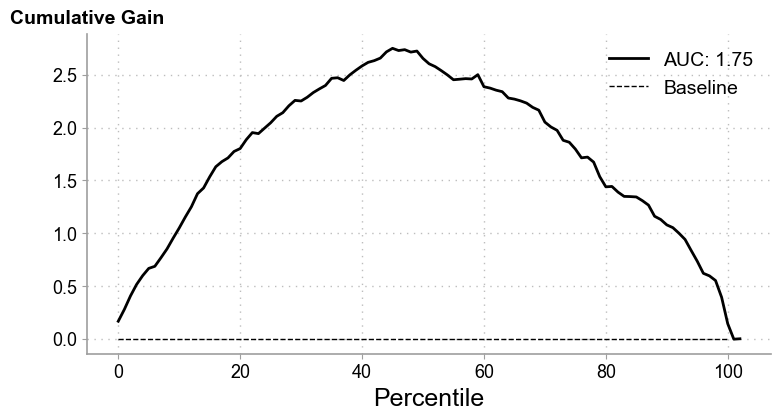

In [30]:
gain_curve_test = relative_cumulative_gain_curve(test_r_learner_pred, "discounts", "sales", prediction="cate")
auc = area_under_the_relative_cumulative_gain_curve(test_r_learner_pred, "discounts", "sales", prediction="cate")

use_plotplainblind("mono")
fig, ax = plt.subplots(figsize=(8, 4.4))
ax.plot(gain_curve_test, color="black", linewidth=2, label=f"AUC: {auc:.2f}")
ax.hlines(0, 0, 100, linestyle="--", color="black", linewidth=1, label="Baseline")
ax.set_xlabel("Percentile")
set_top_ylabel(ax, "Cumulative Gain", fontsize=14, fontweight="bold")
ax.legend(loc="upper right")
plt.tight_layout()

### Visual Intuition for Double-ML

Simulated data: $T$ depends nonlinearly on confounder $X_c$; $Y$ depends on both $T$ and $X_c$ and $X_h$ (effect heterogeneity).

After residualization:
- Confounding by $X_c$ is removed (left plot shows no color pattern)
- Heterogeneity by $X_h$ remains (right plot shows clear grouping)
- Slope of $Y^* | T^*$ within each $X_h$ group reveals the true CATE

In [31]:
np.random.seed(123)
n = 5000

x_h = np.random.randint(1, 4, n)
x_c = np.random.uniform(-1, 1, n)

t = np.random.normal(10 + 1*x_c + 3*x_c**2 + x_c**3, 0.3)
y = np.random.normal(t + x_h*t - 5*x_c - x_c**2 - x_c**3, 0.3)

df_sim = pd.DataFrame(dict(x_h=x_h, x_c=x_c, t=t, y=y))

### Before Residualizing: The Confounder Bends Everything

- Each blob is one value of $x_h$, with true CATEs of 2, 3, and 4, so the ATE is 3
- Shade is the confounder $x_c$, which pushes both $t$ and $y$ nonlinearly
- A naive slope of $y$ on $t$ mixes the effect with $x_c$

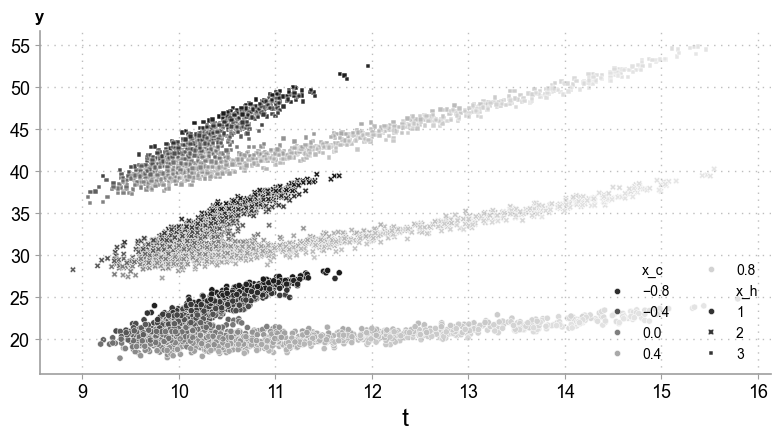

In [35]:
# Facure's raw simulated data
import matplotlib
use_plotplainblind("mono")
fig, ax = plt.subplots(figsize=(8, 4.6))
cmap = matplotlib.colors.LinearSegmentedColormap.from_list("", ["0.1", "0.5", "0.9"])
sns.scatterplot(data=df_sim, y="y", x="t", hue="x_c", style="x_h", palette=cmap, ax=ax, s=20)
ax.set_xlabel("t")
ax.set_ylabel("")
set_top_ylabel(ax, "y", fontsize=12, fontweight="bold")
ax.legend(fontsize=10, ncol=2)
plt.tight_layout()

In [32]:
debias_m = HistGradientBoostingRegressor(max_depth=3)
denoise_m = HistGradientBoostingRegressor(max_depth=3)

t_res = cross_val_predict(debias_m, df_sim[["x_c"]], df_sim["t"], cv=10)
y_res = cross_val_predict(denoise_m, df_sim[["x_c", "x_h"]], df_sim["y"], cv=10)

df_res = df_sim.assign(
    t_res = df_sim["t"] - t_res,
    y_res = df_sim["y"] - y_res
)

### Residualizing Removes the Confounding

- Regress $\tilde{y}$ on $\tilde{t}$ in the simulated data: the slope lands near the true ATE of 3
- The flexible $\hat{\mu}_T$ captured the nonlinear confounding, so OLS on the residuals does not need to

In [37]:
import statsmodels.formula.api as smf
print("ATE from the residual regression:", round(smf.ols("y_res~t_res", data=df_res).fit().params["t_res"], 3))

ATE from the residual regression: 3.055


### Confounding Gone, Heterogeneity Kept

- Left: no pattern in the shade of $x_c$. The data looks as if the treatment were randomized
- Right: the three $x_h$ groups fan out with different slopes, the CATEs we want

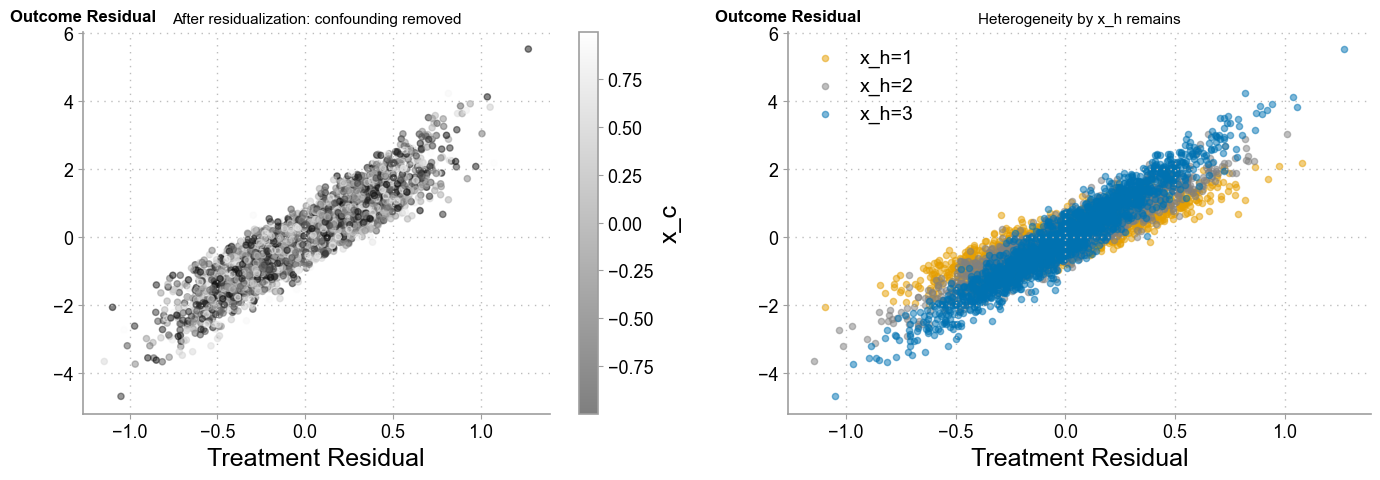

In [33]:
use_plotplainblind("mono")
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Left: residuals colored by x_c (should show no pattern)
cmap = plt.cm.gray
scatter1 = ax1.scatter(df_res["t_res"], df_res["y_res"],
                       c=df_res["x_c"], cmap=cmap, alpha=0.5, s=20)
ax1.set_xlabel("Treatment Residual")
set_top_ylabel(ax1, "Outcome Residual", fontsize=12, fontweight="bold")
ax1.set_title("After residualization: confounding removed", fontsize=11)
plt.colorbar(scatter1, ax=ax1, label="x_c")

# Right: residuals colored by x_h (should show clear grouping)
colors_h = {1: "#E69F00", 2: "gray", 3: "#0072B2"}
for h in [1, 2, 3]:
    mask = df_res["x_h"] == h
    ax2.scatter(df_res[mask]["t_res"], df_res[mask]["y_res"],
                color=colors_h[h], alpha=0.5, s=20, label=f"x_h={h}")
ax2.set_xlabel("Treatment Residual")
set_top_ylabel(ax2, "Outcome Residual", fontsize=12, fontweight="bold")
ax2.set_title("Heterogeneity by x_h remains", fontsize=11)
ax2.legend()

plt.tight_layout()

### $Y^*$ Is the Slope of a Line Through the Origin

Using the R-loss: $Y^* = \tilde{Y} / \tilde{T}$, weighted by $\tilde{T}^2$.

- Both residuals center on zero, so each group's line passes through $(0, 0)$, and the slope through a point is $\tilde{Y}/\tilde{T}$
- Dividing by a $\tilde{T}$ near zero is wildly unstable. The weights $\tilde{T}^2$ mute those points

Each subgroup $x_h$ has a different true CATE (since $Y \sim T + X_h \cdot T$):
- $x_h = 1$: CATE approx 2
- $x_h = 2$: CATE approx 3
- $x_h = 3$: CATE approx 4

In [34]:
df_star = df_res.assign(
    y_star = df_res["y_res"]/df_res["t_res"],
    weight = df_res["t_res"]**2,
)

for x in range(1, 4):
    cate = np.average(df_star.query(f"x_h=={x}")["y_star"],
                      weights=df_star.query(f"x_h=={x}")["weight"])
    print(f"CATE x_h={x}", cate)

CATE x_h=1 2.021737047693798
CATE x_h=2 2.983950016613336
CATE x_h=3 3.9994094567384932


### The Weights Mute the Noisy Points Near $\tilde{T} = 0$

- Point size is the weight $\tilde{T}^2$
- Near the center, $Y^*$ runs off to $\pm 2{,}000$ (cut off here), but those points weigh almost nothing
- Dashed lines: weighted averages by group, close to the true 2, 3, and 4

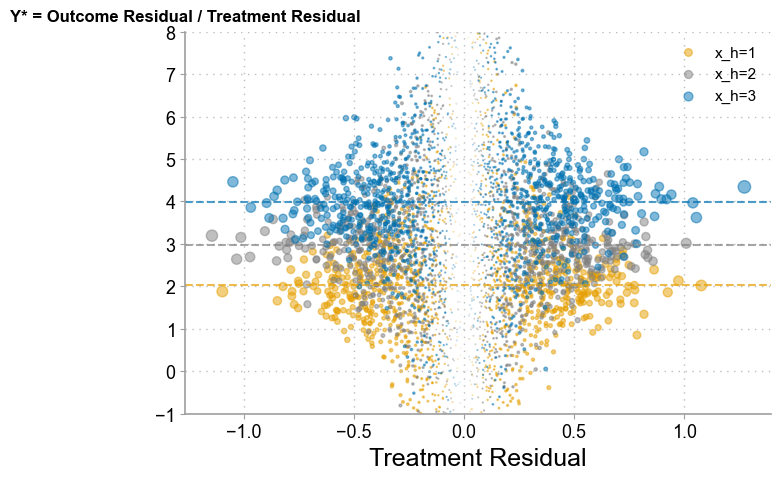

In [35]:
use_plotplainblind("mono")
fig, ax = plt.subplots(figsize=(8, 5))

colors_h = {1: "#E69F00", 2: "gray", 3: "#0072B2"}
for h in [1, 2, 3]:
    mask = df_star["x_h"] == h
    ax.scatter(df_star[mask]["t_res"], df_star[mask]["y_star"],
               color=colors_h[h], alpha=0.5, s=df_star[mask]["weight"]*50,
               label=f"x_h={h}")

# Add horizontal lines for group CATEs
cate_1 = np.average(df_star.query("x_h==1")["y_star"], weights=df_star.query("x_h==1")["weight"])
cate_2 = np.average(df_star.query("x_h==2")["y_star"], weights=df_star.query("x_h==2")["weight"])
cate_3 = np.average(df_star.query("x_h==3")["y_star"], weights=df_star.query("x_h==3")["weight"])

ax.axhline(cate_1, color="#E69F00", linestyle="--", linewidth=1.5, alpha=0.7)
ax.axhline(cate_2, color="gray", linestyle="--", linewidth=1.5, alpha=0.7)
ax.axhline(cate_3, color="#0072B2", linestyle="--", linewidth=1.5, alpha=0.7)

ax.set_xlabel("Treatment Residual")
set_top_ylabel(ax, "Y* = Outcome Residual / Treatment Residual", fontsize=12, fontweight="bold")
ax.set_ylim(-1, 8)
ax.legend(fontsize=11)
plt.tight_layout()

### Tree-Based and Neural Net Learners

<b style="color:#73000A;">Tree-based metalearners</b> (causal trees, causal forests)
- Athey & Wager pioneered using modified trees for CATE
- Learn splits that maximize heterogeneity, not prediction
- Available in econml and causalml
- Causal forests get their own lecture (19)

<b style="color:#73000A;">Neural network metalearners</b>
- Still nascent; complexity not yet worth the gain
- Curth & Schaar, Shalit et al. have theoretical papers

For now, the four learners (T, X, S, R) cover most use cases.

### The Four Side by Side

| | Data per model | Wins when | Fails when |
|---|---|---|---|
| <b style="color:#73000A;">T</b> | one arm each | both arms large | one arm thin, effect small |
| <b style="color:#73000A;">S</b> | pooled | continuous $T$, quick baseline | learner shrinks $T$ away |
| <b style="color:#73000A;">X</b> | pooled via imputation | arms very unbalanced | stage 1 models poor |
| <b style="color:#73000A;">R</b> | pooled residuals | confounding handled by nuisances | nuisance models poor |

- No dominant row: the choice is about <b style="color:#73000A;">where your data is thin</b> and <b style="color:#73000A;">which model you trust</b>
- Every row still owes the same identification debt: unconfoundedness given $x$, and positivity

## Key Ideas

- <b style="color:#73000A;">Metalearners</b> repurpose flexible ML models for CATE estimation
- <b style="color:#73000A;">T-learner:</b> fit separate outcome models per treatment arm; simple but prone to regularization bias
- <b style="color:#73000A;">X-learner:</b> two-stage; uses propensity weights to handle imbalanced treatment/control
- <b style="color:#73000A;">S-learner:</b> single model with T as a feature; simple, tends to bias CATE toward zero
- <b style="color:#73000A;">Double-ML (R-learner):</b> residualize T and Y via cross-validated ML, regress on residuals; debiases even with nonlinear confounding
- All assume <b style="color:#73000A;">unconfoundedness:</b> no unmeasured confounders in $X$